In [44]:
%pip install -q xgboost

Note: you may need to restart the kernel to use updated packages.


In [34]:
import xgboost as xgb

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [35]:
# load feature-engineered dataset from Week 4
df = pd.read_csv(
    "04_feature_engineered_data.csv",
    dtype={
        "PostalCode": "string",
        "School_District": "string"
    },
    parse_dates=["CloseDate"],
    low_memory=False
)

# use original train/test split
train = df[df["dataset_split"] == "train"].copy()
test = df[df["dataset_split"] == "test"].copy()

print("Feature-engineered dataset loaded!")
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Feature-engineered dataset loaded!
Training shape: (94162, 23)
Testing shape: (12339, 23)


In [36]:
# prepare features for XGBoost

numeric_features = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Latitude",
    "Longitude",
    "ParkingTotal",
    "Property_Age",
    "Bed_Bath_Ratio"
]

categorical_features = [
    "PostalCode",
    "FireplaceYN",
    "NewConstructionYN",
    "City",
    "CountyOrParish",
    "ViewYN",
    "MLSAreaMajor",
    "AttachedGarageYN",
    "School_District"
]

features = numeric_features + categorical_features
target = "ClosePrice"

for data in [train, test]:
    for col in numeric_features:
        # converts numeric columns to valid numeric types
        data[col] = pd.to_numeric(data[col], errors="coerce")
    
    # converts categorical columns to strings and replaces missing values
    for col in categorical_features:
        data[col] = (data[col].astype("string").fillna("Missing").astype(str))

    # removes rows with missing close prices
    data[target] = pd.to_numeric(data[target], errors="coerce")

train = train.dropna(subset=[target])
test = test.dropna(subset=[target])

X_train = train[features].copy()
X_test = test[features].copy()

y_train = train[target].to_numpy(float)
y_test = test[target].to_numpy(float)

print("Total features:", len(features))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Total features: 19
Training shape: (94162, 19)
Testing shape: (12339, 19)


In [37]:
# Numeric preprocessing
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant",fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [38]:
# create and train initial XGBoost model with fixed set of hyperparameters
xgb_baseline = XGBRegressor(
    n_estimators=200, # number of boosting trees
    max_depth=6,
    learning_rate=0.1, # controls contribution of each new tree
    objective="reg:squarederror",
    random_state=42,
    n_jobs=4,
    tree_method="hist")

# Create pipeline
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_baseline)])

# Train model
baseline_pipeline.fit(X_train, y_train)

# Predict on test data
baseline_predictions = baseline_pipeline.predict(X_test)

print("Baseline XGBoost training complete!")

Baseline XGBoost training complete!


In [39]:
# Define evaluation function to evaluate R^2, MAE, RMSE, MdAPE
def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    r2 = r2_score(actual, predicted)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    valid = actual != 0

    mdape = 100 * np.median(
        np.abs(predicted[valid] - actual[valid]) /
        np.abs(actual[valid])
    ) if valid.any() else np.nan

    return {
        "Test R²": r2,
        "MAE ($)": mae,
        "RMSE ($)": rmse,
        "MdAPE (%)": mdape}


# Evaluate baseline model
baseline_metrics = calculate_metrics(y_test, baseline_predictions)

# Display results
baseline_results = pd.DataFrame([{
    "Model": "Baseline XGBoost",
    **baseline_metrics}])

print("BASELINE XGBOOST TEST RESULTS")

display(baseline_results.round(4))

BASELINE XGBOOST TEST RESULTS


,Model,Test R²,MAE ($),RMSE ($),MdAPE (%)
0,Baseline XGBoost,0.855,212121.591,377956.2248,12.4799


In [40]:
# Sort training data by closing date
sort_positions = np.argsort(
    train["CloseDate"].to_numpy(),
    kind="stable")

X_train_sorted = (
    X_train.iloc[sort_positions]
    .reset_index(drop=True))

y_train_sorted = y_train[sort_positions]

# Define parameter search space
param_grid = {
    "model__max_depth": [3, 4, 5, 6, 7],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.07, 0.1],
    "model__n_estimators": [100, 200, 300, 500],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.8, 0.9, 1.0],
    "model__reg_lambda": [1, 5, 10]
}

# Initialize XGBoost model
xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=4,
    tree_method="hist"
)

# Build tuning pipeline
tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_tuning)
])

# Time-series cross-validation
cv = TimeSeriesSplit(n_splits=3)

# Randomized hyperparameter search
xgb_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Run tuning
xgb_search.fit(
    X_train_sorted,
    y_train_sorted
)

print("\nHyperparameter tuning complete!")

print("\nBest Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation R²:")
print(round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Hyperparameter tuning complete!

Best Parameters:
{'model__subsample': 1.0, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}

Best Cross-Validation R²:
0.8544


In [41]:
# Retrieve best model
best_xgb = xgb_search.best_estimator_

# Predict on full test set
tuned_predictions = best_xgb.predict(X_test)

# Calculate metrics
tuned_metrics = calculate_metrics(
    y_test,
    tuned_predictions
)

# Create results table
tuned_results = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    **tuned_metrics
}])

print("TUNED XGBOOST TEST RESULTS")

print("\nBest Hyperparameters:")
print(xgb_search.best_params_)

print("\nTest properties evaluated:", len(y_test))

display(tuned_results.round(4))

TUNED XGBOOST TEST RESULTS

Best Hyperparameters:
{'model__subsample': 1.0, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}

Test properties evaluated: 12339


,Model,Test R²,MAE ($),RMSE ($),MdAPE (%)
0,Tuned XGBoost,0.8685,195154.0457,359936.453,11.182


In [42]:
# Compare baseline and tuned XGBoost using test R²

models = {
    "Baseline XGBoost": baseline_pipeline,
    "Tuned XGBoost": best_xgb
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    metrics = calculate_metrics(
        y_test, predictions
    )

    results.append({
        "Model": name,
        **metrics
    })

final_results = pd.DataFrame(results)

final_results = final_results.sort_values(
    "Test R²",
    ascending=False
).reset_index(drop=True)

print("FINAL XGBOOST MODEL COMPARISON")

display(final_results.round(4))

print("\nHighest observed test R²:")
print(final_results.iloc[0]["Model"])

print(
    "R²:",
    round(final_results.iloc[0]["Test R²"], 4)
)

FINAL XGBOOST MODEL COMPARISON


,Model,Test R²,MAE ($),RMSE ($),MdAPE (%)
0,Tuned XGBoost,0.8685,195154.0457,359936.4530,11.1820
1,Baseline XGBoost,0.8550,212121.5910,377956.2248,12.4799



Highest observed test R²:
Tuned XGBoost
R²: 0.8685


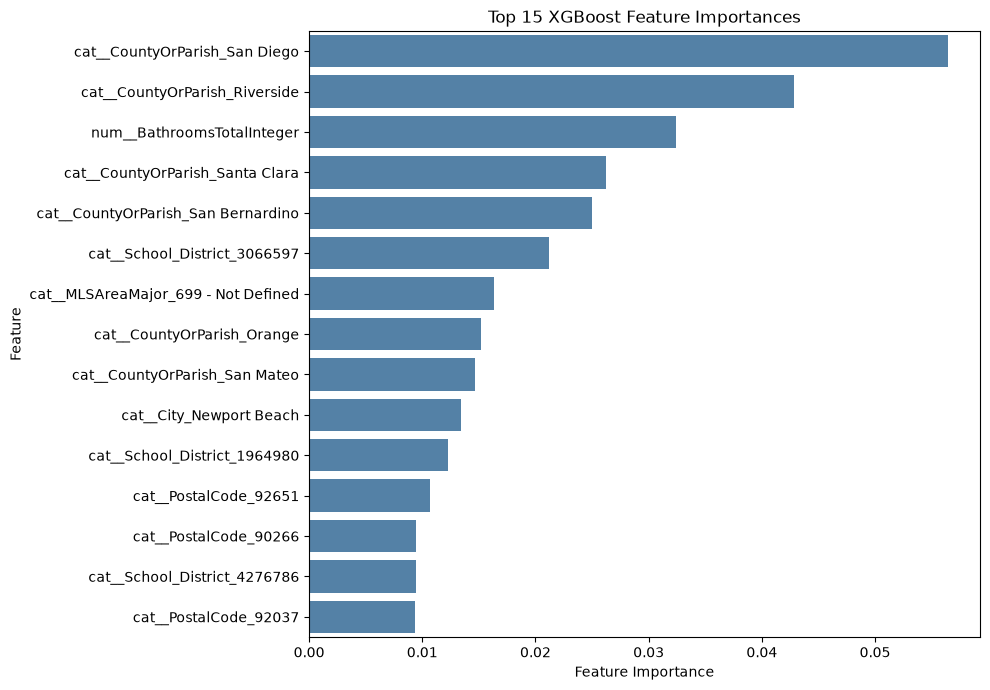

,Feature,Importance
2821,cat__CountyOrParish_San Diego,0.056449
2817,cat__CountyOrParish_Riverside,0.042873
2,num__BathroomsTotalInteger,0.032374
2827,cat__CountyOrParish_Santa Clara,0.026188
2820,cat__CountyOrParish_San Bernardino,0.024978
4137,cat__School_District_3066597,0.021187
3129,cat__MLSAreaMajor_699 - Not Defined,0.016353
2812,cat__CountyOrParish_Orange,0.015226
2825,cat__CountyOrParish_San Mateo,0.014645
2400,cat__City_Newport Beach,0.013407


In [43]:
# Get trained XGBoost model
xgb_model = best_xgb.named_steps["model"]

# Get fitted preprocessor
fitted_preprocessor = best_xgb.named_steps[
    "preprocessor"
]

# Retrieve feature names
feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Get feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort features
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

# Select top 15 features
top_features = importance_df.head(15)

# Visualize
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(top_features)